# 1. La place de la France dans l'IA : retard et opacité

Données : base *Notable AI Models* d'Epoch AI (une ligne par modèle d'IA jugé notable).

Ce notebook répond à deux questions :

- **Partie A — le retard.** Combien de modèles notables et de modèles de pointe la France produit-elle, et à quel niveau de puissance de calcul, comparée aux États-Unis, à la Chine, au Royaume-Uni, à l'Allemagne et au Canada ?
- **Partie B — l'opacité.** Les développeurs publient-ils de moins en moins d'informations sur leurs modèles ?

**Hypothèses posées avant l'analyse**

1. La France produit peu de modèles de pointe, et l'écart de puissance de calcul avec les États-Unis se mesure en années.
2. Sa présence repose sur un très petit nombre d'acteurs.
3. La part de modèles dont la puissance de calcul est publiée diminue depuis 2020, surtout pour les modèles fermés.
4. Les modèles aux poids ouverts sont mieux documentés que les modèles fermés.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import FIGURES
from style import COULEURS_PAYS, ORDRE_PAYS, appliquer_style
appliquer_style()
FIGURES.mkdir(exist_ok=True)
import analyses

## 0. Chargement et premier contrôle

In [2]:
from nettoyage import charger_dernier, preparer_epoch, eclater_pays, annees_de_retard, INFOS_PUBLIABLES

brut = charger_dernier("epoch_notable_models")
print(f"{brut.shape[0]} modèles, {brut.shape[1]} colonnes")
brut.head(3)

Lecture locale : data/raw/epoch_notable_models_2026-11-22.csv
1102 modèles, 20 colonnes


,Model,Organization,Publication date,Domain,Task,Parameters,Training compute (FLOP),Training dataset size (total),Confidence,Organization categorization,Country (of organization),Notability criteria,Training hardware,Training compute cost (2023 USD),Model accessibility,Open model weights?,Frontier model,Training compute notes,Parameters notes,Dataset size notes
0,Gemini 4 Carbon,Google DeepMind,2026-11-10,"Language,Multimodal,Vision","Language modeling/generation,Image Understandi...",NaN,NaN,NaN,Unknown,Industry,United States of America,Discretionary,NaN,NaN,API access,No,NaN,NaN,NaN,NaN
1,Claude Mythos 5.2,Anthropic,2026-11-09,"Language,Multimodal,Vision","Language modeling/generation,Chat,Question ans...",NaN,NaN,NaN,Confident,Industry,United States of America,"SOTA improvement,Significant use,Training cost",NaN,NaN,Limited access,NaN,NaN,NaN,NaN,NaN
2,Claude Fable 5.2,Anthropic,2026-11-09,"Language,Multimodal,Vision","Language modeling/generation,Chat,Question ans...",NaN,NaN,NaN,Confident,Industry,United States of America,"SOTA improvement,Significant use,Training cost",NaN,NaN,API access,No,NaN,NaN,NaN,NaN


In [3]:
epoch = preparer_epoch(brut)
print(f"{len(brut) - len(epoch)} modèles écartés faute de date de publication")
print(f"Période couverte : {epoch['annee'].min()} - {epoch['annee'].max()}")
epoch[["Model", "Organization", "Country (of organization)", "annee", "ouvert", "frontiere", "score_transparence"]].head()

0 modèles écartés faute de date de publication
Période couverte : 1950 - 2026


,Model,Organization,Country (of organization),annee,ouvert,frontiere,score_transparence
0,Gemini 4 Carbon,Google DeepMind,United States of America,2026,False,False,0
1,Claude Mythos 5.2,Anthropic,United States of America,2026,False,False,0
2,Claude Fable 5.2,Anthropic,United States of America,2026,False,False,0
3,Inkling 2 Small,Thinking Machines,United States of America,2026,True,False,4
4,Ripple-65B Preview,Ricursive Intelligence,NaN,2026,True,False,2


### Taux de remplissage des variables

Avant toute analyse : quelles colonnes sont exploitables ? C'est aussi le premier résultat de la partie B — une valeur manquante peut signifier que le développeur n'a pas publié l'information.

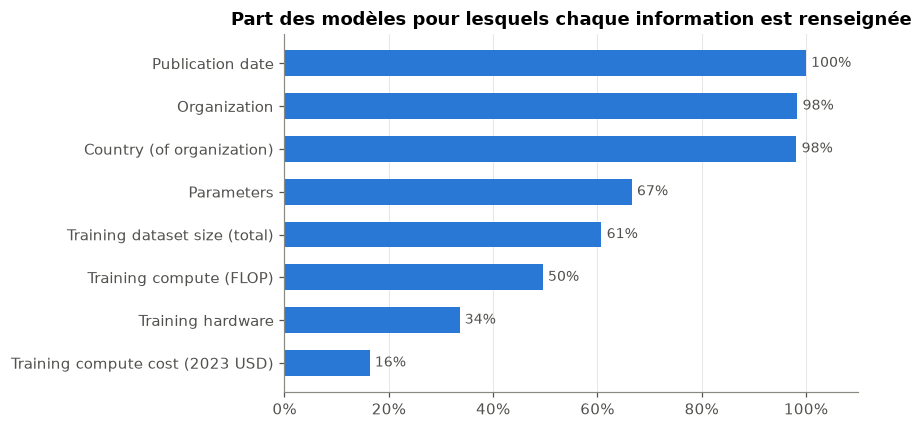

In [4]:
colonnes = ["Organization", "Country (of organization)", "Publication date", "Parameters",
            "Training compute (FLOP)", "Training dataset size (total)",
            "Training hardware", "Training compute cost (2023 USD)"]
remplissage = brut[colonnes].notna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(remplissage.index, remplissage.values, color="#2a78d6", height=0.6)
for y, v in enumerate(remplissage.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Part des modèles pour lesquels chaque information est renseignée")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "01_remplissage.png")

**Interprétation.** Seules l'organisation, le pays et la date sont presque toujours renseignés (98 à 100 %). Le nombre de paramètres (67 %), la taille des données (61 %) et la puissance de calcul (50 %) sont connus pour une partie seulement des modèles. Nous les utilisons donc de deux façons, comme variables d'analyse sur les modèles où elles existent, et comme indicateurs d'opacité quand elles manquent. Le coût d'entraînement n'est connu que pour 16 % des modèles, il ne peut donc pas servir de variable centrale.

## Partie A — Le retard de la France

### A.1 Pays des modèles

Un modèle co-développé par plusieurs pays est réparti entre eux à parts égales (**comptage fractionnaire**). Le comptage entier, où le modèle compte pour 1 dans chaque pays, sert de test de robustesse juste après.

In [5]:
par_pays = eclater_pays(epoch)

# Collaboration internationale : au moins deux pays différents parmi les organisations du modèle
pays_distincts = epoch["Country (of organization)"].dropna().str.split(",").map(lambda l: len({p.strip() for p in l}))
print("Collaborations internationales :", (pays_distincts > 1).sum())
synthese = (par_pays.groupby("pays")
            .agg(modeles=("poids", "sum"),
                 dont_frontiere=("poids", lambda p: p[par_pays.loc[p.index, "frontiere"]].sum()),
                 part_ouverts=("ouvert", lambda o: o.astype("float").mean()),
                 premiere_annee=("annee", "min"))
            .reindex(ORDRE_PAYS).round(2))
synthese["part_du_total"] = (synthese["modeles"] / synthese["modeles"].sum()).round(3)
synthese

Collaborations internationales : 168


,modeles,dont_frontiere,part_ouverts,premiere_annee,part_du_total
pays,,,,,
France,28.70,0.50,0.71,2005,0.026
États-Unis,643.92,85.33,0.43,1950,0.584
Chine,169.27,4.17,0.59,2014,0.154
Royaume-Uni,72.47,8.50,0.23,1968,0.066
Allemagne,21.47,3.50,0.74,1994,0.019
Canada,42.80,6.50,0.44,1988,0.039
Autres,123.37,15.50,0.57,1969,0.112


**Interprétation.** Parmi les six pays comparés, la France arrive cinquième avec 28,7 modèles notables, soit 2,6 % du total, derrière les États-Unis (58 %), la Chine (15 %), le Royaume-Uni et le Canada, et juste devant l'Allemagne. Elle n'a que 0,5 modèle de pointe, contre 85 pour les États-Unis et 4 pour la Chine. En revanche, 71 % de ses modèles sont ouverts, contre 43 % aux États-Unis et 59 % en Chine, ce qui confirme une stratégie tournée vers les modèles ouverts, que partage l'Allemagne (74 %).

#### Test de robustesse : comptage entier

Le comptage fractionnaire répartit un modèle entre les pays des organisations qui l'ont développé. En **comptage entier**, le modèle compte 1 pour chaque pays participant. Si le classement change beaucoup d'une méthode à l'autre, la position d'un pays dépend surtout de ses collaborations.

In [6]:
robustesse = pd.DataFrame({
    "fractionnaire": eclater_pays(epoch, "fractionnaire").groupby("pays")["poids"].sum(),
    "entier": eclater_pays(epoch, "entier").groupby("pays")["poids"].sum(),
}).reindex(ORDRE_PAYS)
robustesse["rapport entier / fractionnaire"] = robustesse["entier"] / robustesse["fractionnaire"]
robustesse.round(2)

,fractionnaire,entier,rapport entier / fractionnaire
pays,,,
France,28.70,52.0,1.81
États-Unis,643.92,710.0,1.10
Chine,169.27,195.0,1.15
Royaume-Uni,72.47,89.0,1.23
Allemagne,21.47,31.0,1.44
Canada,42.80,58.0,1.36
Autres,123.37,171.0,1.39


**Interprétation.** La France est le pays pour lequel le rapport est le plus élevé (1,81), loin devant l'Allemagne (1,44) et les États-Unis (1,10). Beaucoup de modèles français sont donc des collaborations, en particulier avec le laboratoire parisien de Facebook AI Research, souvent associé à l'INRIA ou à des universités françaises (voir A.6). La présence française mesurée en A.1 dépend ainsi en partie d'une entreprise américaine.

### A.2 Évolution du nombre de modèles notables

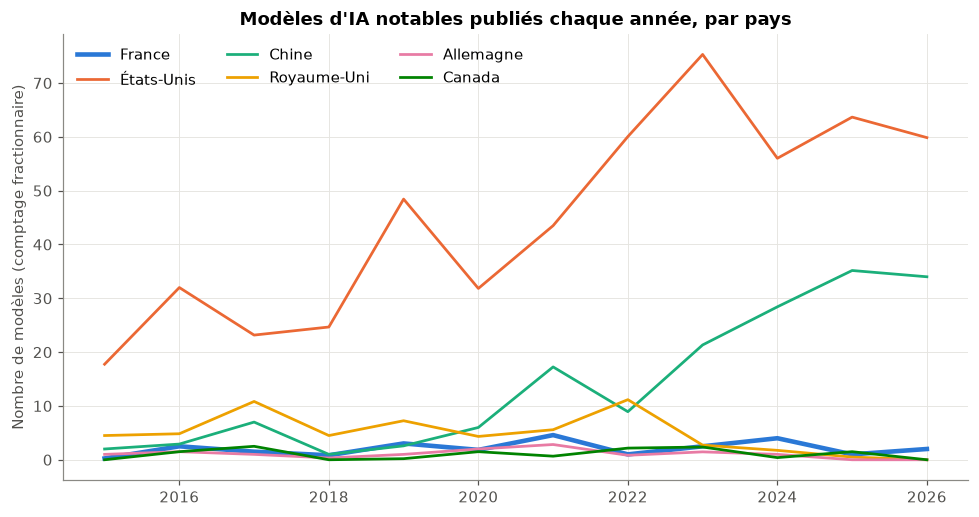

In [7]:
compte = (par_pays.groupby(["annee", "pays"])["poids"].sum()
          .unstack(fill_value=0).reindex(columns=ORDRE_PAYS, fill_value=0))
compte = compte.loc[compte.index >= 2015]

fig, ax = plt.subplots()
for pays in ORDRE_PAYS:
    if pays == "Autres":
        continue
    ax.plot(compte.index, compte[pays], color=COULEURS_PAYS[pays], label=pays,
            linewidth=3 if pays == "France" else 1.8)
ax.set_title("Modèles d'IA notables publiés chaque année, par pays")
ax.set_ylabel("Nombre de modèles (comptage fractionnaire)")
ax.legend(ncol=3, loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "02_modeles_par_an.png")

In [8]:
# Part de chaque pays, par période de 3 ans : plus lisible que des comptes annuels
par_pays["periode"] = pd.cut(par_pays["annee"], bins=[2014, 2017, 2020, 2023, 2026],
                             labels=["2015-17", "2018-20", "2021-23", "2024-26"])
parts = (par_pays.groupby(["periode", "pays"], observed=True)["poids"].sum()
         .groupby(level=0).transform(lambda s: s / s.sum()).unstack()
         .reindex(columns=ORDRE_PAYS).fillna(0))
parts.style.format("{:.1%}")

pays,France,États-Unis,Chine,Royaume-Uni,Allemagne,Canada,Autres
periode,,,,,,,
2015-17,3.2%,54.8%,9.0%,15.2%,2.6%,3.0%,12.2%
2018-20,3.7%,67.7%,6.2%,10.4%,2.2%,1.1%,8.8%
2021-23,2.8%,61.9%,16.4%,6.7%,1.8%,1.8%,8.6%
2024-26,2.2%,57.4%,31.2%,0.7%,0.3%,0.6%,7.6%


**Interprétation.** La part de la France recule légèrement, de 3,2 % sur 2015-2017 et 3,7 % sur 2018-2020 à 2,2 % sur 2024-2026. La Chine, elle, passe de 6 % à 31 % des modèles notables en dix ans, et c'est surtout elle qui prend des parts aux États-Unis et au Royaume-Uni.

### A.3 Puissance de calcul : la course à l'échelle

La puissance de calcul (en FLOP) varie sur plusieurs ordres de grandeur : on la représente en **échelle logarithmique**. Les seuls modèles présents ici sont ceux dont la puissance de calcul est connue (voir partie B pour le biais que cela introduit).

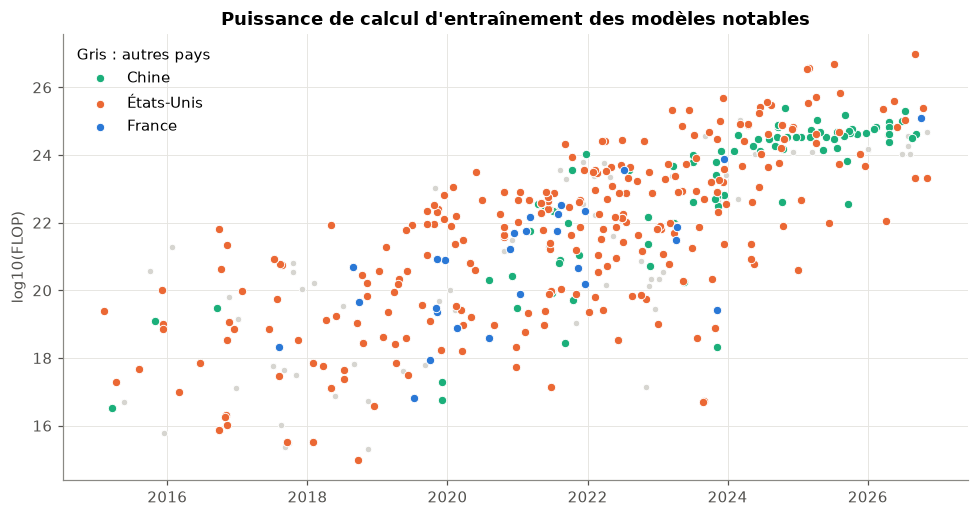

In [9]:
calc = par_pays.dropna(subset=["log10_calcul"])
calc = calc.loc[calc["annee"] >= 2015]

fig, ax = plt.subplots()
for pays in ["Autres", "Royaume-Uni", "Allemagne", "Canada", "Chine", "États-Unis", "France"]:
    sous = calc.loc[calc["pays"] == pays]
    gris = pays not in {"France", "États-Unis", "Chine"}
    ax.scatter(sous["date"], sous["log10_calcul"], s=18 if gris else 30,
               color="#d6d5d0" if gris else COULEURS_PAYS[pays],
               edgecolor="white", linewidth=0.6, label=None if gris else pays, zorder=1 if gris else 3)
ax.set_title("Puissance de calcul d'entraînement des modèles notables")
ax.set_ylabel("log10(FLOP)")
ax.legend(title="Gris : autres pays", loc="upper left")
fig.tight_layout(); fig.savefig(FIGURES / "03_calcul_nuage.png")

### A.4 Le record de puissance de calcul, année par année

Pour chaque année, le modèle le plus puissant (en FLOP), et de combien ce record est multiplié par rapport à l'année précédente.

In [10]:
record = analyses.record_par_annee(epoch)
record.loc[record.index >= 2015].style.format({"record (FLOP)": "{:.1e}", "× par rapport à l'année précédente": "{:.1f}"})

,record (FLOP),× par rapport à l'année précédente
annee,,
2015,3.8e+20,nan
2016,6.6e+21,17.4
2017,8.4e+20,0.1
2018,8.7e+21,10.4
2019,1.1e+23,12.3
2020,3.1e+23,2.9
2021,2.0e+24,6.5
2022,2.7e+24,1.3
2023,5.0e+25,18.2


**Interprétation.** Le record est multiplié par environ 100 000 entre 2018 (8,7 × 10²¹ FLOP) et 2026 (9,4 × 10²⁶ FLOP). La progression se fait par sauts, avec des années à ×10 ou plus (2018, 2019, 2023 avec Gemini 1.0 Ultra, 2025 avec Grok 4) et des années où le record ne bouge presque pas. Une baisse comme en 2024 ne veut pas dire que les modèles reculent. Le tableau donne le modèle le plus puissant de chaque année parmi ceux dont la puissance de calcul est connue, et les plus gros modèles de 2024 ne l'ont probablement pas publiée.

### A.5 Le retard exprimé en années

Pour chaque pays et chaque année, on prend le **record** de puissance de calcul atteint jusque-là, puis on cherche en quelle année les États-Unis avaient atteint ce même niveau. La différence est un retard en années ; une valeur négative signifie que le pays était en avance sur les États-Unis cette année-là. Le calcul repose sur des années entières : un écart d'un an peut venir d'un seul modèle.

In [11]:
retard = annees_de_retard(par_pays)
tableau_retard = (retard.pivot(index="annee", columns="pays", values="retard_annees")
                  .reindex(columns=[p for p in ORDRE_PAYS if p not in ("États-Unis", "Autres")]))
tableau_retard.loc[tableau_retard.index >= 2018]

pays,France,Chine,Royaume-Uni,Allemagne,Canada
annee,,,,,
2018,2.0,NaN,2.0,4.0,NaN
2019,3.0,5.0,-1.0,5.0,3.0
2020,4.0,4.0,0.0,4.0,4.0
2021,2.0,0.0,0.0,2.0,5.0
2022,1.0,1.0,1.0,3.0,1.0
2023,2.0,2.0,2.0,3.0,2.0
2024,NaN,1.0,3.0,NaN,NaN
2025,NaN,2.0,NaN,NaN,NaN
2026,3.0,3.0,NaN,NaN,NaN


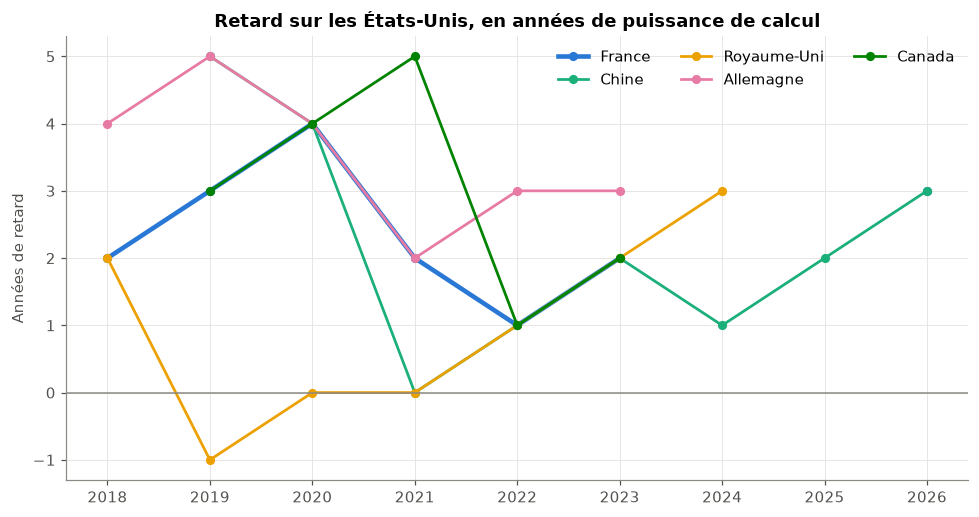

In [12]:
fig, ax = plt.subplots()
for pays in tableau_retard.columns:
    s = tableau_retard[pays]
    s = s[s.index >= 2018]   # les années sans donnée restent vides : pas de ligne tracée par-dessus
    ax.plot(s.index, s.values, marker="o", markersize=5, color=COULEURS_PAYS[pays], label=pays,
            linewidth=3 if pays == "France" else 1.8)
ax.axhline(0, color="#8a8984", linewidth=1)
ax.set_title("Retard sur les États-Unis, en années de puissance de calcul")
ax.set_ylabel("Années de retard")
ax.legend(ncol=3)
fig.tight_layout(); fig.savefig(FIGURES / "04_retard_annees.png")

**Interprétation.** La France ne rattrape pas son retard. Il oscille entre un et quatre ans depuis 2018, et en 2026 son record correspond au niveau que les États-Unis avaient atteint en 2023, soit trois ans de retard. Les années vides (2024, 2025) sont celles où aucun modèle français de l'année n'a de puissance de calcul connue, ce qui rappelle que le calcul dépend de l'information publiée (partie B).

### A.6 Test de robustesse : la France sans Mistral

Hypothèse 2 : la présence française repose sur très peu d'acteurs. On regarde la concentration des modèles français par organisation.

In [13]:
fr = par_pays.loc[par_pays["pays"] == "France"]
concentration = fr.groupby("Organization")["poids"].sum().sort_values(ascending=False)
print(f"{concentration.size} combinaisons d'organisations pour les modèles français ; la première pèse {concentration.iloc[0] / concentration.sum():.0%} des modèles")
concentration.head(10)

31 combinaisons d'organisations pour les modèles français ; la première pèse 28% des modèles


Organization
Mistral AI                                                                       8.000000
Facebook AI Research                                                             5.500000
INRIA                                                                            2.000000
Facebook AI Research,INRIA                                                       1.333333
Hugging Face,BigScience                                                          1.000000
Université Paris-Est                                                             1.000000
LORIA,University of Lorraine,Facebook AI Research                                0.750000
Facebook AI Research,LORIA                                                       0.666667
Facebook,INRIA,Sorbonne University                                               0.666667
INRIA,University of Illinois Urbana-Champaign (UIUC),Ecole Normale Supèrieure    0.666667
Name: poids, dtype: float64

In [14]:
sans_mistral = par_pays.loc[~par_pays["Organization"].str.contains("Mistral", case=False, na=False)]
comparaison = pd.DataFrame({
    "avec Mistral": par_pays.loc[par_pays["pays"] == "France"].groupby("annee")["poids"].sum(),
    "sans Mistral": sans_mistral.loc[sans_mistral["pays"] == "France"].groupby("annee")["poids"].sum(),
}).fillna(0)
comparaison.loc[comparaison.index >= 2018]

,avec Mistral,sans Mistral
annee,,
2018,0.833333,0.833333
2019,3.033333,3.033333
2020,1.833333,1.833333
2021,4.583333,4.583333
2022,1.000000,1.000000
2023,2.500000,1.500000
2024,4.000000,0.000000
2025,1.000000,0.000000
2026,2.000000,0.000000


**Interprétation.** Sans Mistral AI, la France n'a plus aucun modèle notable depuis 2024. Avant 2023, la courbe ne change pas, car Mistral n'existait pas encore. La position récente de la France repose donc entièrement sur une seule entreprise, ce qui confirme l'hypothèse 2 et la rend fragile.

## Partie B — L'opacité des développeurs

### B.1 Qui publie quoi, et depuis quand ?

Pour chaque modèle, on sait si cinq informations ont été rendues publiques : puissance de calcul, nombre de paramètres, taille du jeu de données, coût, matériel. Le **score de transparence** compte ces informations (de 0 à 5).

*Deux limites à garder en tête :*

- **Ce qu'Epoch mesure, c'est l'information connue, pas l'information publiée par le développeur.** Pour un modèle aux poids ouverts, Epoch peut compter lui-même les paramètres ou estimer la puissance de calcul. Une valeur renseignée ne prouve donc pas que le développeur l'a divulguée. Le notebook 4 confronte cette mesure à celle de Stanford, qui note directement les divulgations des développeurs.
- **Délai d'estimation.** Epoch complète ses fiches au fil du temps : pour les modèles des derniers mois, une valeur manquante peut simplement signifier que l'estimation n'est pas encore faite. La baisse sur les toutes dernières années est donc en partie mécanique.

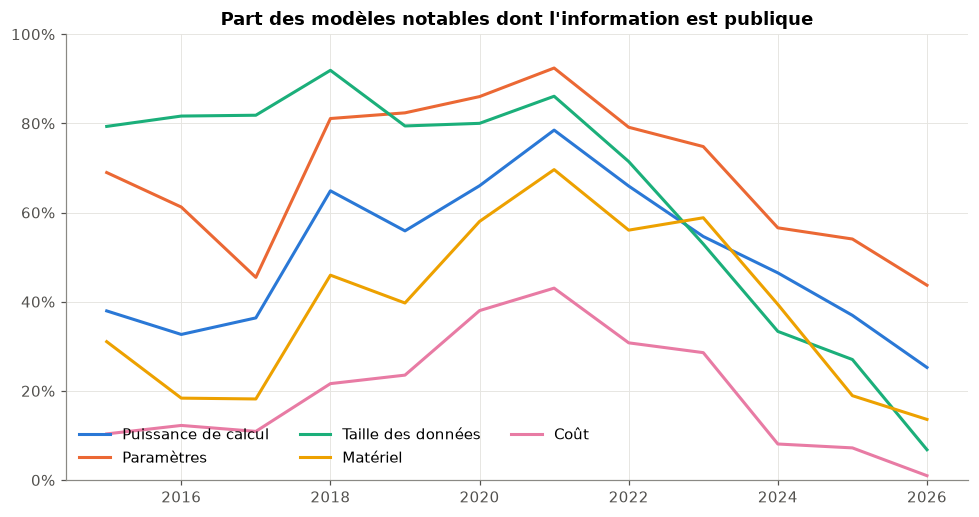

In [15]:
indicateurs = list(INFOS_PUBLIABLES.values())
evolution = epoch.loc[epoch["annee"] >= 2015].groupby("annee")[indicateurs].mean()

fig, ax = plt.subplots()
noms = {"publie_calcul": "Puissance de calcul", "publie_parametres": "Paramètres",
        "publie_donnees": "Taille des données", "publie_materiel": "Matériel", "publie_cout": "Coût"}
couleurs = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for (col, nom), c in zip(noms.items(), couleurs):
    ax.plot(evolution.index, evolution[col], color=c, label=nom)
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_ylim(0, 1)
ax.set_title("Part des modèles notables dont l'information est publique")
ax.legend(ncol=3, loc="lower left")
fig.tight_layout(); fig.savefig(FIGURES / "05_opacite_evolution.png")

**Interprétation.** Toutes les informations reculent après 2021. Le coût est le plus touché, il passe de 43 % des modèles en 2021 à 1 % en 2026, et la taille des données d'entraînement tombe de 71 % en 2022 à 7 % en 2026. La puissance de calcul passe de 78 % à 25 %. Le retournement commence en 2022, l'année où les grands modèles deviennent des produits commerciaux avec ChatGPT.

### B.1 bis — Information publiée ou devinée ?

Une puissance de calcul renseignée dans Epoch n'est pas forcément divulguée par le développeur. Les notes d'Epoch permettent de distinguer trois cas (`qualifier_source_calcul` dans `src/nettoyage.py`) :

- **calculée depuis des infos publiées** : Epoch calcule à partir de ce que le développeur a rendu public (paramètres × jetons d'entraînement, matériel × durée), ou reprend la valeur déclarée ;
- **estimation indirecte** : Epoch la devine (fiabilité « Speculative », ou estimation à partir des scores aux benchmarks ou de modèles comparables) ;
- **non renseignée**.

La règle de classement repose sur des mots-clés dans les notes : on la vérifie à la main sur un échantillon (cellule suivante).

source_calcul,calculée depuis des infos publiées,estimation indirecte,non renseignée
annee,,,
2021,0.67,0.11,0.22
2022,0.60,0.05,0.34
2023,0.41,0.13,0.45
2024,0.41,0.05,0.54
2025,0.30,0.07,0.63
2026,0.20,0.05,0.75


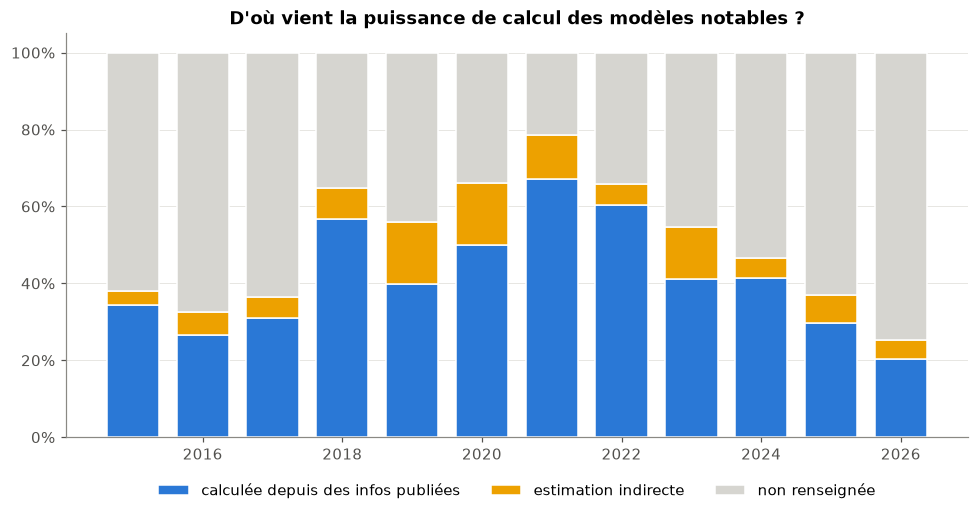

In [16]:
parts_source = (pd.crosstab(epoch.loc[epoch["annee"] >= 2015, "annee"],
                            epoch.loc[epoch["annee"] >= 2015, "source_calcul"], normalize="index")
                .reindex(columns=["calculée depuis des infos publiées", "estimation indirecte", "non renseignée"], fill_value=0))

fig, ax = plt.subplots()
couleurs_source = {"calculée depuis des infos publiées": "#2a78d6", "estimation indirecte": "#eda100", "non renseignée": "#d6d5d0"}
bas = np.zeros(len(parts_source))
for cat, c in couleurs_source.items():
    ax.bar(parts_source.index, parts_source[cat], bottom=bas, color=c, label=cat, width=0.75,
           edgecolor="white", linewidth=1)
    bas += parts_source[cat].values
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("D'où vient la puissance de calcul des modèles notables ?")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIGURES / "06_source_calcul.png")
parts_source.round(2).tail(6)

In [17]:
# Vérification manuelle de la règle : quelques notes classées « estimation indirecte »
if "Training compute notes" in epoch:
    exemples = epoch.loc[epoch["source_calcul"] == "estimation indirecte", ["Model", "Training compute notes"]]
    for _, r in exemples.sample(min(5, len(exemples)), random_state=0).iterrows():
        print(f"- {r['Model']} : {str(r['Training compute notes'])[:200]}\n")

- AudioLM : "We train each stage on 16 TPUv4s with batch size of 256 for 1M steps." That's for the 900M-param transformers If there's 256 passes in each batch, then using 6ND that's 900m * 256m * 6 = 1.3e18. sani

- Pluribus : Trained in 8 days on a 64 core CPU https://ai.facebook.com/blog/pluribus-first-ai-to-beat-pros-in-6-player-poker/ "We trained the blueprint strategy for Pluribus in eight days on a 64-core server and 

- Kimi K3 : Based on peer models such as Kimi K2.6 and DeepSeek V4 Pro, plausibly was trained on roughly 30T tokens (likely between 15T and 60T). Using the heuristic that C = 6ND, 30T pretraining tokens would imp

- Transformer-XL Large + Phrase Induction : Fine-tuned from pre-trained Transformer-XL Large (upd 3.7832771e+20 FLOP, old estimation 1.09e19 FLOP). Total: 3.7832771e20 + 1.588e17 = 3.7848651e+20 FLOP (Speculative confidence same as Transformer 

- Dropout (CIFAR) : "a single NVIDIA GTX 580 GPU. Training on CIFAR-10 takes roughly 90 minutes" p17 1.581 TFLO

**Interprétation.** Les estimations indirectes restent rares, entre 5 % et 13 % des modèles depuis 2021, et leur part n'augmente pas quand la transparence baisse. Les exemples affichés montrent que la règle de classement est raisonnable, même si certains calculs à partir du matériel et de la durée d'entraînement pourraient être classés dans l'une ou l'autre catégorie. Ce qui augmente, c'est la part des modèles dont la puissance de calcul n'est pas renseignée du tout (22 % en 2021, 75 % en 2026), pendant que la part calculée à partir d'informations publiées passe de 67 % à 20 %. La baisse de la courbe B.1 reflète donc surtout un recul de ce que publient les développeurs.

### B.2 Ouvert n'est pas transparent ?

In [18]:
tab = (epoch.loc[(epoch["annee"] >= 2020) & epoch["ouvert"].notna()]
       .assign(statut=lambda d: np.where(d["ouvert"], "poids ouverts", "fermé"))
       .groupby(["statut", "frontiere"])[indicateurs + ["score_transparence"]].mean()
       .rename(index={True: "pointe", False: "autre"}, level=1))
tab.style.format({c: "{:.0%}" for c in indicateurs} | {"score_transparence": "{:.2f}"})

**Interprétation.** Depuis 2020, les modèles ouverts sont nettement mieux documentés que les fermés, avec une puissance de calcul connue pour 69 % d'entre eux contre 32 %, et un score moyen de 3,0 informations sur 5 contre 1,5. Parmi les modèles de pointe, l'écart semble encore plus fort, mais il n'y a que 5 modèles de pointe ouverts contre 39 fermés, donc la comparaison est fragile. Les modèles de pointe fermés sont d'ailleurs mieux documentés que les autres modèles fermés, sans doute parce qu'Epoch estime en priorité la puissance de calcul des modèles les plus importants.

### B.3 Modèles ouverts et fermés, période par période

Part des modèles dont la puissance de calcul est connue, selon la période et selon que les poids du modèle sont publiés ou non.

In [19]:
publication = analyses.tableau_publication(epoch)
publication.style.format({"fermé": "{:.0%}", "poids ouverts": "{:.0%}"})

acces,fermé,poids ouverts,"nombre, fermé","nombre, poids ouverts"
periode,,,,
2018-2020,64%,63%,80,68
2021-2023,55%,75%,147,141
2024-2026,18%,64%,191,122


**Interprétation.** Avant 2021, il n'y avait pas d'écart entre modèles ouverts et fermés (63 % et 64 %). L'écart apparaît à partir de 2021 et vient des modèles fermés, dont la part tombe à 55 % puis à 18 % depuis 2024, alors que celle des modèles ouverts reste entre 64 % et 75 %. Chaque case compte entre 68 et 191 modèles, ce qui suffit pour que ces écarts ne reposent pas sur quelques cas.

### B.4 Avant / après l'AI Act (2 août 2025)

Comparaison **descriptive**. Attention au délai d'estimation d'Epoch (voir B.1) : les modèles postérieurs à août 2025 sont les plus récents, donc ceux dont les fiches sont les moins complètes. Une baisse après l'AI Act ne peut pas être lue comme un effet de la réglementation. La comparaison entre signataires et non-signataires, qui neutralise en partie ce biais, est dans le notebook 4.

In [20]:
recent = epoch.loc[epoch["date"] >= "2024-01-01"]
recent.groupby("apres_ai_act")[indicateurs + ["score_transparence"]].agg(["mean", "count"]).T

apres_ai_act                   False       True 
publie_calcul      mean     0.461039    0.264151
                   count  154.000000  159.000000
publie_parametres  mean     0.564935    0.465409
                   count  154.000000  159.000000
publie_donnees     mean     0.344156    0.106918
                   count  154.000000  159.000000
publie_cout        mean     0.097403    0.012579
                   count  154.000000  159.000000
publie_materiel    mean     0.331169    0.144654
                   count  154.000000  159.000000
score_transparence mean     1.798701    0.993711
                   count  154.000000  159.000000

## Synthèse

Les hypothèses 1 et 2 sont confirmées. La France produit peu de modèles notables (2,6 % du total) et presque aucun modèle de pointe, elle a entre un et quatre ans de retard sur les États-Unis en puissance de calcul, et depuis 2024 sa présence repose uniquement sur Mistral AI. L'hypothèse 3 est confirmée aussi, la part des modèles dont la puissance de calcul est connue passant de 78 % en 2021 à 25 % en 2026, avec une baisse qui vient surtout des modèles fermés. L'hypothèse 4 n'est vraie qu'à partir de 2021, quand les modèles fermés deviennent beaucoup moins documentés que les ouverts.

Les deux parties sont liées. Les modèles dont la puissance de calcul est inconnue sont absents des parties A.3 à A.5, et ce sont surtout des modèles fermés, souvent américains et de pointe. Le record américain est donc probablement sous-estimé. Le rapport final (partie 3.6) discute ce que cela change pour la mesure du retard.